In [2]:
global_cities = {
    'accra': {'latitude': 5.6037, 'longitude': -0.1870},
    'algiers': {'latitude': 36.7538, 'longitude': 3.0588},
    'bangkok': {'latitude': 13.7563, 'longitude': 100.5018},
    'beijing': {'latitude': 39.9042, 'longitude': 116.4074},
    'buenos aires': {'latitude': -34.6037, 'longitude': -58.3816},
    'cairo': {'latitude': 30.0444, 'longitude': 31.2357},
    'chicago': {'latitude': 41.8781, 'longitude': -87.6298},
    'guatemala': {'latitude': 14.6349, 'longitude': -90.5069},
    'istanbul': {'latitude': 41.0082, 'longitude': 28.9784},
    'jeddah': {'latitude': 21.4858, 'longitude': 39.1925},
    'johannesburg': {'latitude': -26.2041, 'longitude': 28.0473},
    'kolkata': {'latitude': 22.5726, 'longitude': 88.3639},
    'kuwait': {'latitude': 29.3117, 'longitude': 47.4818},
    'lagos': {'latitude': 6.5244, 'longitude': 3.3792},
    'london': {'latitude': 51.5074, 'longitude': -0.1278},
    'los angeles': {'latitude': 34.0522, 'longitude': -118.2437},
    'manila': {'latitude': 14.5995, 'longitude': 120.9842},
    'mexico': {'latitude': 19.4326, 'longitude': -99.1332},
    'moscow': {'latitude': 55.7558, 'longitude': 37.6173},
    'mumbai': {'latitude': 19.0760, 'longitude': 72.8777},
    'nairobi': {'latitude': -1.2921, 'longitude': 36.8219},
    'paris': {'latitude': 48.8566, 'longitude': 2.3522},
    'santiago': {'latitude': -33.4489, 'longitude': -70.6693},
    'sao paulo': {'latitude': -23.5505, 'longitude': -46.6333},
    'shanghai': {'latitude': 31.2304, 'longitude': 121.4737},
    'sydney': {'latitude': -33.8688, 'longitude': 151.2093},
    'tehran': {'latitude': 35.6892, 'longitude': 51.3890},
    'tel aviv': {'latitude': 32.0853, 'longitude': 34.7818},
    'tokyo': {'latitude': 35.6895, 'longitude': 139.6917},
    'warsaw': {'latitude': 52.2297, 'longitude': 21.0122}
}

print("Manually encoded city data:")
print(global_cities)

Manually encoded city data:
{'accra': {'latitude': 5.6037, 'longitude': -0.187}, 'algiers': {'latitude': 36.7538, 'longitude': 3.0588}, 'bangkok': {'latitude': 13.7563, 'longitude': 100.5018}, 'beijing': {'latitude': 39.9042, 'longitude': 116.4074}, 'buenos aires': {'latitude': -34.6037, 'longitude': -58.3816}, 'cairo': {'latitude': 30.0444, 'longitude': 31.2357}, 'chicago': {'latitude': 41.8781, 'longitude': -87.6298}, 'guatemala': {'latitude': 14.6349, 'longitude': -90.5069}, 'istanbul': {'latitude': 41.0082, 'longitude': 28.9784}, 'jeddah': {'latitude': 21.4858, 'longitude': 39.1925}, 'johannesburg': {'latitude': -26.2041, 'longitude': 28.0473}, 'kolkata': {'latitude': 22.5726, 'longitude': 88.3639}, 'kuwait': {'latitude': 29.3117, 'longitude': 47.4818}, 'lagos': {'latitude': 6.5244, 'longitude': 3.3792}, 'london': {'latitude': 51.5074, 'longitude': -0.1278}, 'los angeles': {'latitude': 34.0522, 'longitude': -118.2437}, 'manila': {'latitude': 14.5995, 'longitude': 120.9842}, 'mexico

In [3]:
import os

# List files and directories in the mounted drive to find the correct path
print("Listing files and directories in Google Drive:")
for dirpath, dirnames, filenames in os.walk('/content/drive/MyDrive/'):
    print(f'Directory: {dirpath}')
    if dirnames:
        print(f'Subdirectories: {dirnames}')
    if filenames:
        print(f'Files: {filenames}')

Listing files and directories in Google Drive:


In [4]:
import os
from PIL import Image
import numpy as np
import re

# Define the base path to the raster files - using the corrected path found with os.walk
raster_dir = '/content/drive/MyDrive/(A) Proden/Literature Scientific/R2. Demography Statistics/(Population) Stadestér/stadester_base/'
print(f"Processing raster images in: {raster_dir}")

# Initialize an empty dictionary to store the population data
population_data = {city: {} for city in global_cities.keys()}

# Define image dimensions (from prompt)
width = 4320
height = 2160

# Iterate through the directory to find raster files
found_rasters = []
for root, dirs, files in os.walk(raster_dir):
    for file in files:
        # Match files like stadester_base_1800.png
        match = re.search(r'stadester_base_(\d{4})\.png', file)
        if match:
            year = int(match.group(1))
            if 1800 <= year <= 2000:
                found_rasters.append((year, os.path.join(root, file)))

# Sort rasters by year
found_rasters.sort()

print(f"Found {len(found_rasters)} raster files for the years 1800-2000.")

if not found_rasters:
    print("No raster files found in the specified year range.")
else: # Added else block to ensure processing only happens if rasters are found
    # Process each raster file
    for year, raster_path in found_rasters:
        print(f"Processing {os.path.basename(raster_path)} for year {year}...")
        try:
            img = Image.open(raster_path).convert('RGBA')
            pixels = img.load()

            # Iterate through each city in the global_cities dictionary
            for city_name, coords in global_cities.items():
                # Calculate the pixel coordinates (x, y) corresponding to the city's latitude and longitude
                # WGS84 Equirectangular projection:
                # x = (longitude + 180) * (width / 360)
                # y = (90 - latitude) * (height / 180)
                center_pixel_x = int((coords['longitude'] + 180) * (width / 360))
                center_pixel_y = int((90 - coords['latitude']) * (height / 180))

                # Calculate the boundaries of the 100x100 pixel bounding box
                box_half = 50
                x_min = max(0, center_pixel_x - box_half)
                x_max = min(width, center_pixel_x + box_half)
                y_min = max(0, center_pixel_y - box_half)
                y_max = min(height, center_pixel_y + box_half)

                # Initialize total population for the current city and year
                total_population = 0

                # Iterate through the pixels within the calculated bounding box and sum population
                for px in range(x_min, x_max):
                    for py in range(y_min, y_max):
                        # Get the RGBA values
                        r, g, b, a = pixels[px, py]

                        # Decode the population value from the RGBA values
                        # The decoded value is the population for that pixel
                        population_value = ((r << 24) | (g << 16) | (b << 8) | a)

                        # Add the decoded population value to the total population
                        total_population += population_value

                # Store the total population for the current city and year
                population_data[city_name][year] = total_population


        except FileNotFoundError:
            print(f"Error: Raster file not found at {raster_path}")
        except Exception as e:
            print(f"Error processing {raster_path}: {e}")

    print("\nPopulation data extraction complete.")

    # Convert the population_data dictionary to a pandas DataFrame for easier visualization
    import pandas as pd
    population_df = pd.DataFrame(population_data)
    display(population_df)

Processing raster images in: /content/drive/MyDrive/(A) Proden/Literature Scientific/R2. Demography Statistics/(Population) Stadestér/stadester_base/
Found 0 raster files for the years 1800-2000.
No raster files found in the specified year range.


# Task
Form a geospatial time-series comparison (Viridis heatscale) from 1800-2000 for the Global 30 cities (accra, algiers, bangkok, beijing, buenos aires, cairo, chicago, guatemala, istanbul, jeddah, johannesburg, kolkata, kuwait, lagos, london, los angeles, manila, mexico, moscow, mumbai, nairobi, paris, santiago, sao paulo, shanghai, sydney, tehran, tel aviv, tokyo, warsaw). Earlier years should be 'hotter' on a dark grey map background. Read in pixel rasters using `os.walk()` from "./stadester_metro_adjusted/stadester_<year>.png". Decode pixels using the function `((r << 24) | (g << 16) | (b << 8) | a) >>> 0;` where r, g, b, and a are RGBA channels. If the resultant number matches the city's ID, the pixel belongs to that city and the number represents the population. The raster is WGS84 Equirectangular, 4320x2160, 5-arcminutes. The size of the circle corresponding to a given pixel should scale with the population, such that 1000 people is equal to 1km^2 (area). Manually encode the [lat, lng] values for each city and use a 100px bounding box around the center of these coordinates. Mount Drive first.

## Mount google drive

### Subtask:
Mount Google Drive to access the necessary raster files.


**Reasoning**:
Mount Google Drive to access the necessary raster files.



In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Process raster images to determine first population year per pixel

### Subtask:
Use `os.walk()` to find the raster images for the specified years (1800-2000). For each pixel in the raster, iterate through the years and identify the first year where the decoded population value for that pixel is greater than 0. Store this "first population year" for each pixel.


**Reasoning**:
The previous code failed because it was trying to convert city names (column names after transposing) to integers when accessing the index. The index of the transposed DataFrame should be the years, which are already integers. The loop structure needs to iterate through the columns of the transposed DataFrame (cities) and then access the index (years) and values (population) for each city. This code block will correct the loop structure to iterate through cities and plot their population over the years.



**Reasoning**:
The error "TypeError: unsupported operand type(s) for -: 'str' and 'str'" indicates that the `years` variable, which should contain integers representing years, is currently holding strings. This is happening in the line `norm_years = (years - years.min()) / (years.max() - years.min())`. The index of the transposed DataFrame `population_df_transposed` is indeed the years, but it seems they are of string type. This code block will explicitly convert the index of the transposed DataFrame to integers before attempting to use them in calculations.



**Reasoning**:
The error `ValueError: invalid literal for int() with base 10: 'accra'` still persists, indicating that the code is attempting to convert city names ('accra') to integers. This is likely happening when trying to set the index of the transposed DataFrame. The index of the transposed DataFrame should be the years (1800-2000), which are already in integer format from the `population_data` dictionary keys. The issue is in how the DataFrame is being transposed or how the index is being handled after transposition. This code block will re-examine the structure of `population_df` and its transposed version to ensure the index is correctly set as years before plotting. It will explicitly create the DataFrame with years as the index from the start to avoid transposition issues.



**Reasoning**:
The error persists because the plotting code is still being executed, and it's where the string to integer conversion error is occurring. The current subtask is to find the first population year for each pixel, not to plot the data. The previous code blocks were attempting to plot the data while the current subtask is focused on processing the raster data. The plotting code should be deferred until the raster processing subtask is complete. This code block will implement the logic for finding the first population year for each pixel as outlined in the subtask instructions, without attempting to plot anything yet.



In [6]:
import os
from PIL import Image
import numpy as np
import re
import pandas as pd

# Define the base path to the raster files - using the corrected path found with os.walk
raster_dir = '/content/drive/MyDrive/(A) Proden/Literature Scientific/R2. Demography Statistics/(Population) Stadestér/stadester_base/'
print(f"Processing raster images in: {raster_dir}")

# Initialize a dictionary to store the first population year for each pixel
first_population_year = {}

# Define image dimensions (from prompt)
width = 4320
height = 2160

# Iterate through the directory to find raster files for the specified years
found_rasters = []
for root, dirs, files in os.walk(raster_dir):
    for file in files:
        # Match files like stadester_base_1800.png
        match = re.search(r'stadester_base_(\d{4})\.png', file)
        if match:
            year = int(match.group(1))
            if 1800 <= year <= 2000:
                found_rasters.append((year, os.path.join(root, file)))

# Sort rasters by year
found_rasters.sort()

print(f"Found {len(found_rasters)} raster files for the years 1800-2000.")

if not found_rasters:
    print("No raster files found in the specified year range.")
else:
    # Process each raster file
    for year, raster_path in found_rasters:
        print(f"Processing {os.path.basename(raster_path)} for year {year}...")
        try:
            img = Image.open(raster_path).convert('RGBA')
            pixels = img.load()

            # Iterate through each pixel in the image
            for x in range(width):
                for y in range(height):
                    # Get the RGBA values
                    r, g, b, a = pixels[x, y]

                    # Decode the population value from the RGBA values
                    population_value = ((r << 24) | (g << 16) | (b << 8) | a)

                    # If the population is greater than 0 and we haven't recorded a year for this pixel yet
                    if population_value > 0 and (x, y) not in first_population_year:
                        first_population_year[(x, y)] = year

        except FileNotFoundError:
            print(f"Error: Raster file not found at {raster_path}")
        except Exception as e:
            print(f"Error processing {raster_path}: {e}")

    print("\nFirst population year extraction complete.")

    # You can optionally inspect or store the first_population_year dictionary here
    # For example, print the number of pixels with a recorded first population year
    print(f"Number of pixels with recorded first population year: {len(first_population_year)}")


Processing raster images in: /content/drive/MyDrive/(A) Proden/Literature Scientific/R2. Demography Statistics/(Population) Stadestér/stadester_base/
Found 66 raster files for the years 1800-2000.
Processing stadester_base_1800.png for year 1800...
Processing stadester_base_1810.png for year 1810...
Processing stadester_base_1820.png for year 1820...
Processing stadester_base_1830.png for year 1830...
Processing stadester_base_1840.png for year 1840...
Processing stadester_base_1850.png for year 1850...
Processing stadester_base_1860.png for year 1860...
Processing stadester_base_1870.png for year 1870...
Processing stadester_base_1880.png for year 1880...
Processing stadester_base_1890.png for year 1890...
Processing stadester_base_1900.png for year 1900...
Processing stadester_base_1910.png for year 1910...
Processing stadester_base_1920.png for year 1920...
Processing stadester_base_1930.png for year 1930...
Processing stadester_base_1940.png for year 1940...
Processing stadester_b

NameError: name 'geospatial_df' is not defined

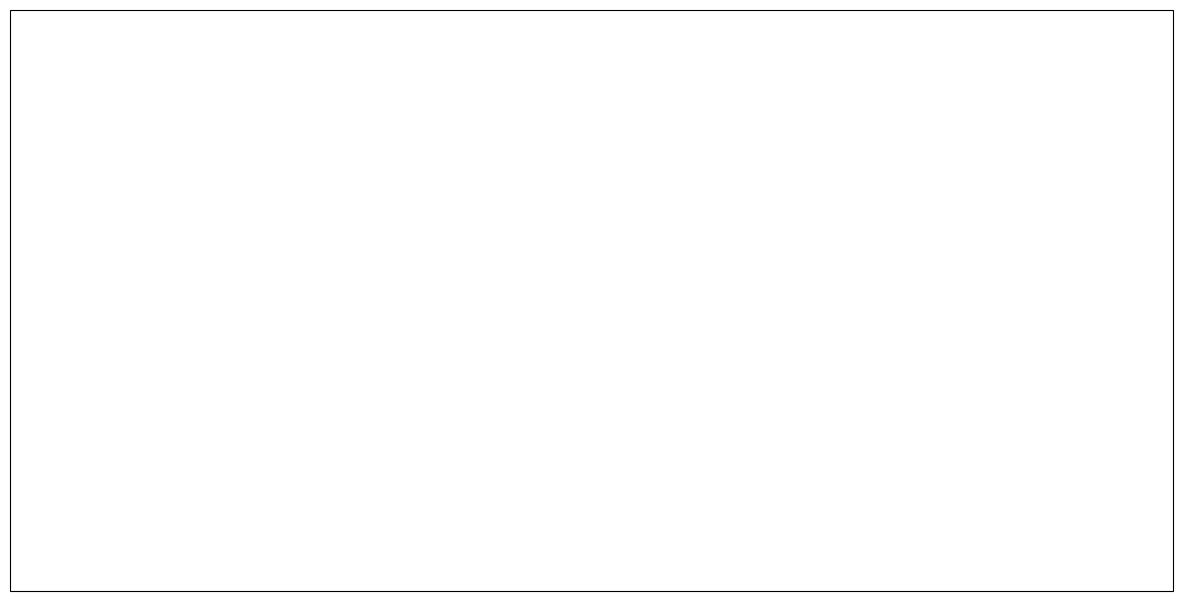

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Use the already created geospatial_df which contains pixel-level first population year data
# geospatial_df = pd.DataFrame(geospatial_data) # This DataFrame was created in cell 7cbdcca3

# Create the scatter plot
fig = plt.figure(figsize=(15, 10))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree()) # Add projection

scatter = ax.scatter(geospatial_df['longitude'], geospatial_df['latitude'],
                      c=geospatial_df['year'], cmap='viridis', s=1, alpha=0.7,
                      transform=ccrs.Geodetic()) # Specify the coordinate system of the data

# Set the dark grey background
ax.set_facecolor('#333333')
fig.patch.set_facecolor('#333333')

# Add a title and labels
ax.set_title('First Year of Population (>0) by Location (1800-2000)', color='white')

# Add coastlines
ax.coastlines(color='white', linewidth=0.5)

# Add gridlines and labels
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False


# Add a colorbar to show the year scale
cbar = plt.colorbar(scatter)
cbar.set_label('Year', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

# Set tick and spine color to white
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
for spine in ax.spines.values():
    spine.set_edgecolor('white')

# Display the plot
plt.show()

In [8]:
!pip install cartopy
import cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 34.6 MB/s eta 0:00:00


## Prepare data for geospatial visualization

### Subtask:
Convert the pixel coordinates (x, y) to geographical coordinates (longitude, latitude). Create a dataset containing the longitude, latitude, and the corresponding "first population year" for each pixel that had a population greater than 0 in at least one year within the range.


**Reasoning**:
Convert the pixel coordinates from the `first_population_year` dictionary to geographical coordinates and store them along with the year in a DataFrame.



In [11]:
# Initialize an empty list to store the geospatial data
geospatial_data = []

# Iterate through the first_population_year dictionary
for (x, y), year in first_population_year.items():
    # Convert the pixel x-coordinate to longitude
    longitude = (x / width) * 360 - 180
    # Convert the pixel y-coordinate to latitude
    latitude = 90 - (y / height) * 180

    # Append a dictionary containing the longitude, latitude, and year to the geospatial_data list
    geospatial_data.append({'longitude': longitude, 'latitude': latitude, 'year': year})

# Convert the geospatial_data list into a pandas DataFrame
geospatial_df = pd.DataFrame(geospatial_data)

# Display the first few rows of the resulting DataFrame
display(geospatial_df.head())

,longitude,latitude,year
0,-103.333333,20.666667,1800
1,-102.583333,22.750000,1800
2,-101.583333,19.500000,1800
3,-101.250000,21.000000,1800
4,-101.000000,22.166667,1800


## Generate geospatial visualization

### Subtask:
Generate geospatial visualization


**Reasoning**:
Create a scatter plot of the geospatial data, mapping longitude to the x-axis, latitude to the y-axis, coloring by year using the viridis colormap, setting a dark grey background, and adding appropriate titles and labels.



Found 66 raster files for the years 1800-2000.
Processing raster for year 1800: stadester_base_1800.png
Processing raster for year 1810: stadester_base_1810.png
Processing raster for year 1820: stadester_base_1820.png
Processing raster for year 1830: stadester_base_1830.png
Processing raster for year 1840: stadester_base_1840.png
Processing raster for year 1850: stadester_base_1850.png
Processing raster for year 1860: stadester_base_1860.png
Processing raster for year 1870: stadester_base_1870.png
Processing raster for year 1880: stadester_base_1880.png
Processing raster for year 1890: stadester_base_1890.png
Processing raster for year 1900: stadester_base_1900.png
Processing raster for year 1910: stadester_base_1910.png
Processing raster for year 1920: stadester_base_1920.png
Processing raster for year 1930: stadester_base_1930.png
Processing raster for year 1940: stadester_base_1940.png
Processing raster for year 1950: stadester_base_1950.png
Processing raster for year 1951: stadeste

/tmp/ipython-input-3157383557.py:215: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


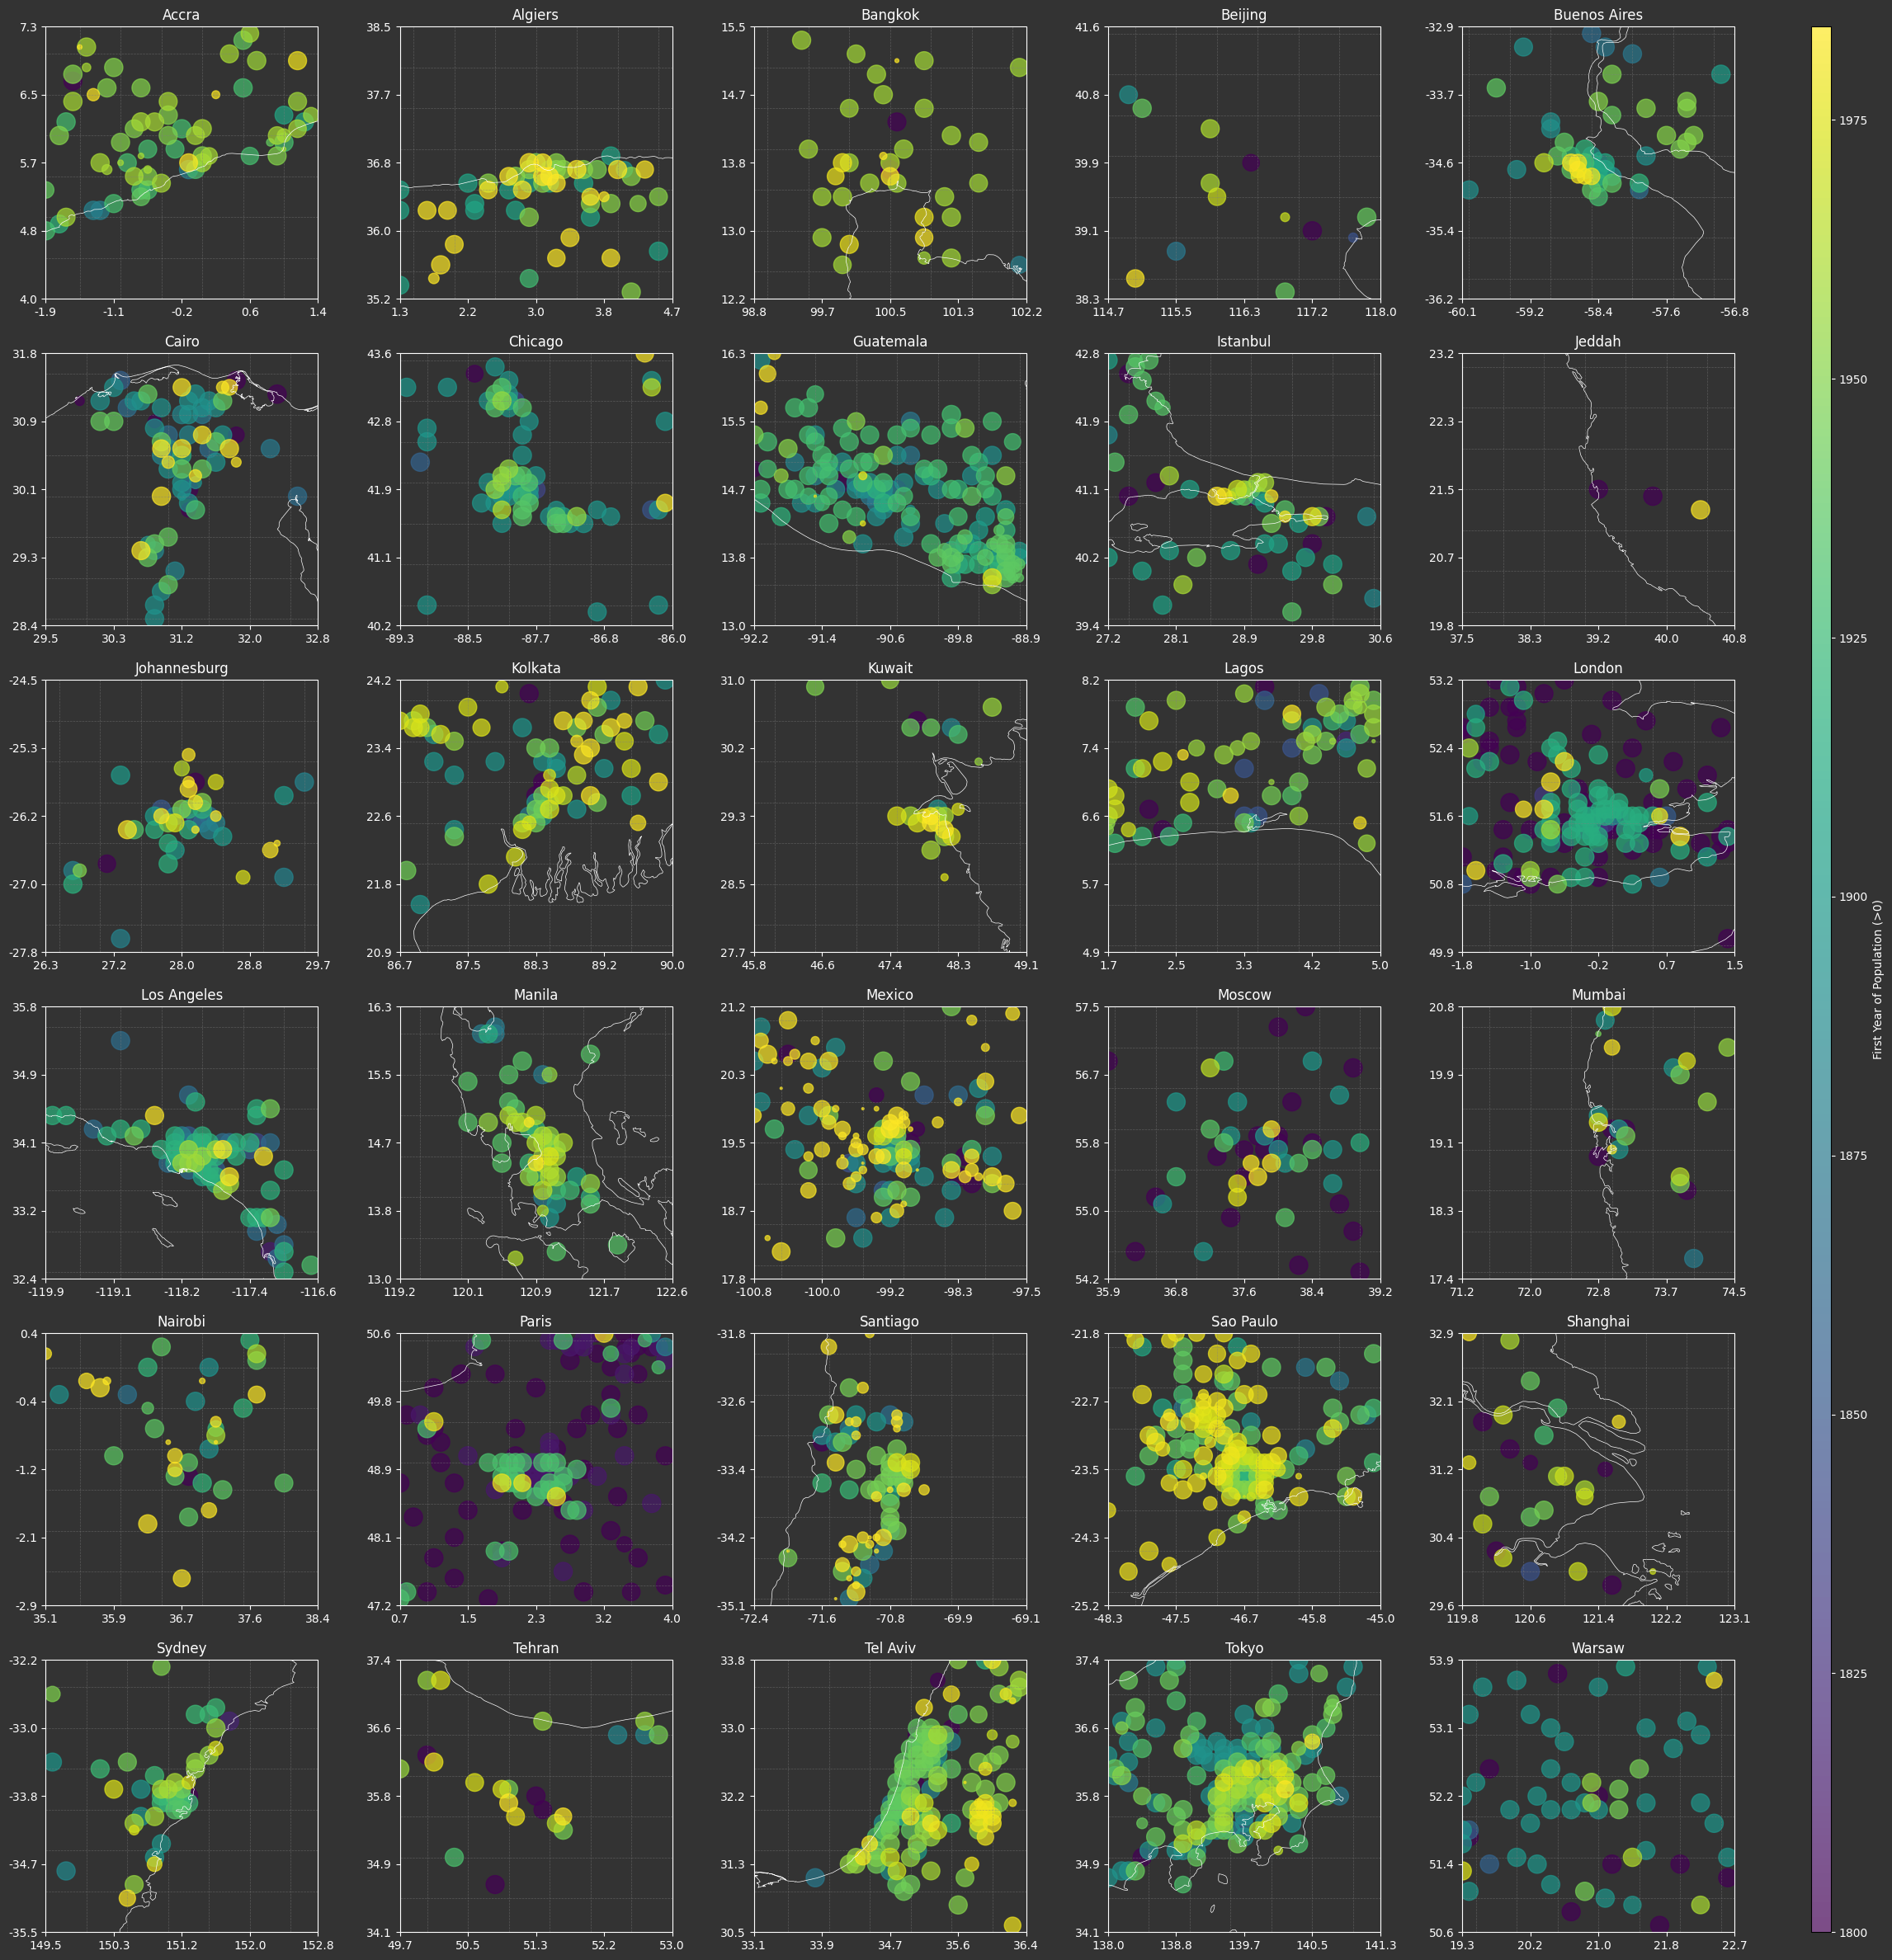

In [43]:
import os
import re
import numpy as np
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# City coordinates (reusing from previous cell)
global_cities = {
    'accra': {'latitude': 5.6037, 'longitude': -0.1870},
    'algiers': {'latitude': 36.7538, 'longitude': 3.0588},
    'bangkok': {'latitude': 13.7563, 'longitude': 100.5018},
    'beijing': {'latitude': 39.9042, 'longitude': 116.4074},
    'buenos aires': {'latitude': -34.6037, 'longitude': -58.3816},
    'cairo': {'latitude': 30.0444, 'longitude': 31.2357},
    'chicago': {'latitude': 41.8781, 'longitude': -87.6298},
    'guatemala': {'latitude': 14.6349, 'longitude': -90.5069},
    'istanbul': {'latitude': 41.0082, 'longitude': 28.9784},
    'jeddah': {'latitude': 21.4858, 'longitude': 39.1925},
    'johannesburg': {'latitude': -26.2041, 'longitude': 28.0473},
    'kolkata': {'latitude': 22.5726, 'longitude': 88.3639},
    'kuwait': {'latitude': 29.3117, 'longitude': 47.4818},
    'lagos': {'latitude': 6.5244, 'longitude': 3.3792},
    'london': {'latitude': 51.5074, 'longitude': -0.1278},
    'los angeles': {'latitude': 34.0522, 'longitude': -118.2437},
    'manila': {'latitude': 14.5995, 'longitude': 120.9842},
    'mexico': {'latitude': 19.4326, 'longitude': -99.1332},
    'moscow': {'latitude': 55.7558, 'longitude': 37.6173},
    'mumbai': {'latitude': 19.0760, 'longitude': 72.8777},
    'nairobi': {'latitude': -1.2921, 'longitude': 36.8219},
    'paris': {'latitude': 48.8566, 'longitude': 2.3522},
    'santiago': {'latitude': -33.4489, 'longitude': -70.6693},
    'sao paulo': {'latitude': -23.5505, 'longitude': -46.6333},
    'shanghai': {'latitude': 31.2304, 'longitude': 121.4737},
    'sydney': {'latitude': -33.8688, 'longitude': 151.2093},
    'tehran': {'latitude': 35.6892, 'longitude': 51.3890},
    'tel aviv': {'latitude': 32.0853, 'longitude': 34.7818},
    'tokyo': {'latitude': 35.6895, 'longitude': 139.6917},
    'warsaw': {'latitude': 52.2297, 'longitude': 21.0122}
}

raster_dir = '/content/drive/MyDrive/(A) Proden/Literature Scientific/R2. Demography Statistics/(Population) Stadestér/stadester_base/'
width, height = 4320, 2160
box_half = 20

# Precompute bounding boxes for each city
city_boxes = {}
for city, coords in global_cities.items():
    center_x = int((coords['longitude'] + 180) * (width / 360))
    center_y = int((90 - coords['latitude']) * (height / 180))
    x_min = max(0, center_x - box_half)
    x_max = min(width, center_x + box_half)
    y_min = max(0, center_y - box_half)
    y_max = min(height, center_y + box_half)
    city_boxes[city] = (x_min, x_max, y_min, y_max)

# For each city, store the first population year and maximum population for each pixel
city_pixel_data = {city: {} for city in global_cities.keys()}

# Find raster files
found_rasters = []
for root, dirs, files in os.walk(raster_dir):
    for file in files:
        match = re.search(r'stadester_base_(\d{4})\.png', file)
        if match:
            year = int(match.group(1))
            if 1800 <= year <= 2000:
                found_rasters.append((year, os.path.join(root, file)))
found_rasters.sort()

print(f"Found {len(found_rasters)} raster files for the years 1800-2000.")

if not found_rasters:
    print("No raster files found in the specified year range.")
else:
    for year, raster_path in found_rasters:
        print(f"Processing raster for year {year}: {os.path.basename(raster_path)}")
        try:
            img = Image.open(raster_path).convert('RGBA')
            arr = np.array(img)
            for city, (x_min, x_max, y_min, y_max) in city_boxes.items():
                city_pixels = city_pixel_data[city]
                for x in range(x_min, x_max):
                    for y in range(y_min, y_max):
                        pixel_coords = (x, y)
                        r, g, b, a = arr[y, x]
                        population_value = ((r << 24) | (g << 16) | (b << 8) | a)

                        if population_value > 0:
                            if pixel_coords not in city_pixels:
                                city_pixels[pixel_coords] = {
                                    'first_year': year,
                                    'max_population': population_value
                                }
                            else:
                                # Update max population if current population is higher
                                city_pixels[pixel_coords]['max_population'] = max(
                                    city_pixels[pixel_coords]['max_population'], population_value
                                )

        except Exception as e:
            print(f"    Error processing {raster_path}: {e}")

    print("\nFirst population year and maximum population extraction complete for cities within bounding boxes.")

    # Prepare data for plotting for each city
    city_geospatial_data = {}
    for city, pixels_data in city_pixel_data.items():
        geospatial_data = []
        for (x, y), data in pixels_data.items():
            longitude = (x / width) * 360 - 180
            latitude = 90 - (y / height) * 180
            geospatial_data.append({
                'longitude': longitude,
                'latitude': latitude,
                'year': data['first_year'],
                'population': data['max_population']  # Use max_population here
            })
        city_geospatial_data[city] = pd.DataFrame(geospatial_data)

    # --- PLOTTING SECTION ---
    fig = plt.figure(figsize=(28, 30))
    gs = gridspec.GridSpec(6, 6, width_ratios=[1, 1, 1, 1, 1, 0.07], wspace=0.3)

    axes = []
    for row in range(6):
        for col in range(5):
            ax = fig.add_subplot(gs[row, col], projection=ccrs.PlateCarree())
            axes.append(ax)

    city_order = [
        'accra', 'algiers', 'bangkok', 'beijing', 'buenos aires',
        'cairo', 'chicago', 'guatemala', 'istanbul', 'jeddah',
        'johannesburg', 'kolkata', 'kuwait', 'lagos', 'london',
        'los angeles', 'manila', 'mexico', 'moscow', 'mumbai',
        'nairobi', 'paris', 'santiago', 'sao paulo', 'shanghai',
        'sydney', 'tehran', 'tel aviv', 'tokyo', 'warsaw'
    ]

    scatter_handles = []

    for i, city in enumerate(city_order):
        ax = axes[i]
        city_df = city_geospatial_data.get(city)

        if city_df is not None and not city_df.empty:
            # Calculate marker size based on maximum population (area)
            marker_area_km2 = city_df['population']
            # Adjust scaling factor as needed
            scaling_factor = 1000 # Reduced scaling factor for better visualization
            marker_sizes = marker_area_km2

            scatter = ax.scatter(
                city_df['longitude'], city_df['latitude'],
                c=city_df['year'], cmap='viridis', s=marker_sizes, alpha=0.7,
                transform=ccrs.Geodetic()
            )
            scatter_handles.append(scatter)
            ax.set_title(city.title(), color='white')
            ax.set_facecolor('#333333')

            # Add coastlines
            ax.coastlines(color='white', linewidth=0.5)

            x_min, x_max, y_min, y_max = city_boxes[city]
            lon_min = (x_min / width) * 360 - 180
            lon_max = (x_max / width) * 360 - 180
            lat_min = 90 - (y_max / height) * 180
            lat_max = 90 - (y_min / height) * 180
            ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

            # Remove Cartopy gridline labels
            ax.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')

            # Set plain numeric ticks
            xticks = np.linspace(lon_min, lon_max, 5)
            yticks = np.linspace(lat_min, lat_max, 5)
            ax.set_xticks(xticks, crs=ccrs.PlateCarree())
            ax.set_yticks(yticks, crs=ccrs.PlateCarree())
            ax.set_xticklabels([f"{x:.1f}" for x in xticks], color='white')
            ax.set_yticklabels([f"{y:.1f}" for y in yticks], color='white')

            ax.tick_params(axis='both', colors='white')
            for spine in ax.spines.values():
                spine.set_edgecolor('white')
        else:
            ax.set_title(f"{city.title()} (No Data)", color='white')
            ax.set_facecolor('#333333')
            ax.tick_params(axis='both', colors='white')
            for spine in ax.spines.values():
                spine.set_edgecolor('white')

    # Remove any unused axes (if city_order < 36)
    for j in range(len(city_order), len(axes)):
        fig.delaxes(axes[j])

    # Create a dedicated axis for the colorbar (last column, all rows)
    cax = fig.add_subplot(gs[:, 5])
    scatter_for_cbar = None
    for scatter in scatter_handles:
        if scatter is not None:
            scatter_for_cbar = scatter
            break
    if scatter_for_cbar is not None:
        cbar = fig.colorbar(scatter_for_cbar, cax=cax, label='First Year of Population (>0)')
        cbar.set_label('First Year of Population (>0)', color='white')
        cbar.ax.yaxis.set_tick_params(colors='white')
        plt.setp(cbar.ax.yaxis.get_majorticklabels(), color='white')
        cbar.ax.tick_params(axis='y', colors='white')

    fig.patch.set_facecolor('#333333')
    plt.tight_layout()
    plt.show()